# Diabetes 130-US Hospitals

## 1. EDA & problem framing

### Downloading necessary libraries

We start by downloading the necessary libraries to better visualize the data

In [158]:
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

### Dataset loading

Load the data from the sklearn library (Diabetes data)

In [159]:
import pandas as pd

from sklearn.datasets import fetch_openml
# Option 3 -- Diabetes 130 Hospitals
diabetes = fetch_openml(data_id=4541, as_frame=True)
X, y = diabetes.data, diabetes.target

# 1.1 Problem Definition

#### Goal: Predict whether a patient will be readmitted to the hospital
#### The data comes from 130 US hospitals between 1999-2008; each row is one hospital stay of a patient with diabetes. The same patient could have several stays.


# 1.2 Target 

#### Readmitted has 3 labels, <30; >30 and NO.

In [160]:
y.value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

#### Check to see there no missing values in the target

In [161]:
y.isna().sum()

np.int64(0)

#### We convert it to binary values (1, 0) maning yes and no respectively.

In [162]:
y = y.map({'NO': 0, '<30': 1, '>30': 1})

#### Check to make sure it works!

In [163]:
y.value_counts()

readmitted
0    54864
1    46902
Name: count, dtype: int64

# 1.3 Visualize the data

In [164]:
df = pd.DataFrame(X, columns=diabetes.feature_names)

In [165]:
df.shape

(101766, 49)

In [166]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 49 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   encounter_id              101766 non-null  int64   
 1   patient_nbr               101766 non-null  int64   
 2   race                      101766 non-null  category
 3   gender                    101766 non-null  category
 4   age                       101766 non-null  category
 5   weight                    101766 non-null  category
 6   admission_type_id         101766 non-null  int64   
 7   discharge_disposition_id  101766 non-null  int64   
 8   admission_source_id       101766 non-null  int64   
 9   time_in_hospital          101766 non-null  int64   
 10  payer_code                101766 non-null  category
 11  medical_specialty         101766 non-null  category
 12  num_lab_procedures        101766 non-null  int64   
 13  num_procedures            101766 non-nul

### We see the data inside each row and as we can see we have some data that has question marks, so we need to change them to NaaNs to have a better view

In [167]:
df.head(10)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,examide,citoglipton,insulin,glyburide.metformin,glipizide.metformin,glimepiride.pioglitazone,metformin.rosiglitazone,metformin.pioglitazone,change,diabetesMed
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,No
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,No,Up,No,No,No,No,No,Ch,Yes
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,No,Yes
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,No,Up,No,No,No,No,No,Ch,Yes
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,No,Steady,No,No,No,No,No,Ch,Yes
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,...,No,No,Steady,No,No,No,No,No,No,Yes
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,...,No,No,Steady,No,No,No,No,No,Ch,Yes
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,...,No,No,No,No,No,No,No,No,No,Yes
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,...,No,No,Steady,No,No,No,No,No,Ch,Yes
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,...,No,No,Steady,No,No,No,No,No,Ch,Yes


#### We create a list called cols_count that includes the countable features in our dataset. Below we can see the descriptive statistics of said features.

##### Below we can see the stays in the hospitals range between 1 to 14 days.
##### We can see that for each patient, there needs to be AT LEAST 1 lab procedure.

In [168]:
cols_count = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
df[cols_count].describe()

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


# 1.4 Cleaning the Data

##### We do a missingno matrix and immediately see that there are no missing values, which is strange. After reviewing the data, we can see that there are ?'s in these columns (weight, medical specialty, payer_code and race). 
##### We also saw that there is a 'None' value in the A1Cresult and max_glu_serum which means no test was performed.
##### Moreover, the gender column has 3 stays which are were recorded as Unknown/Invalid.
##### We also check for duplicated in our data and see that there are none.

<Axes: >

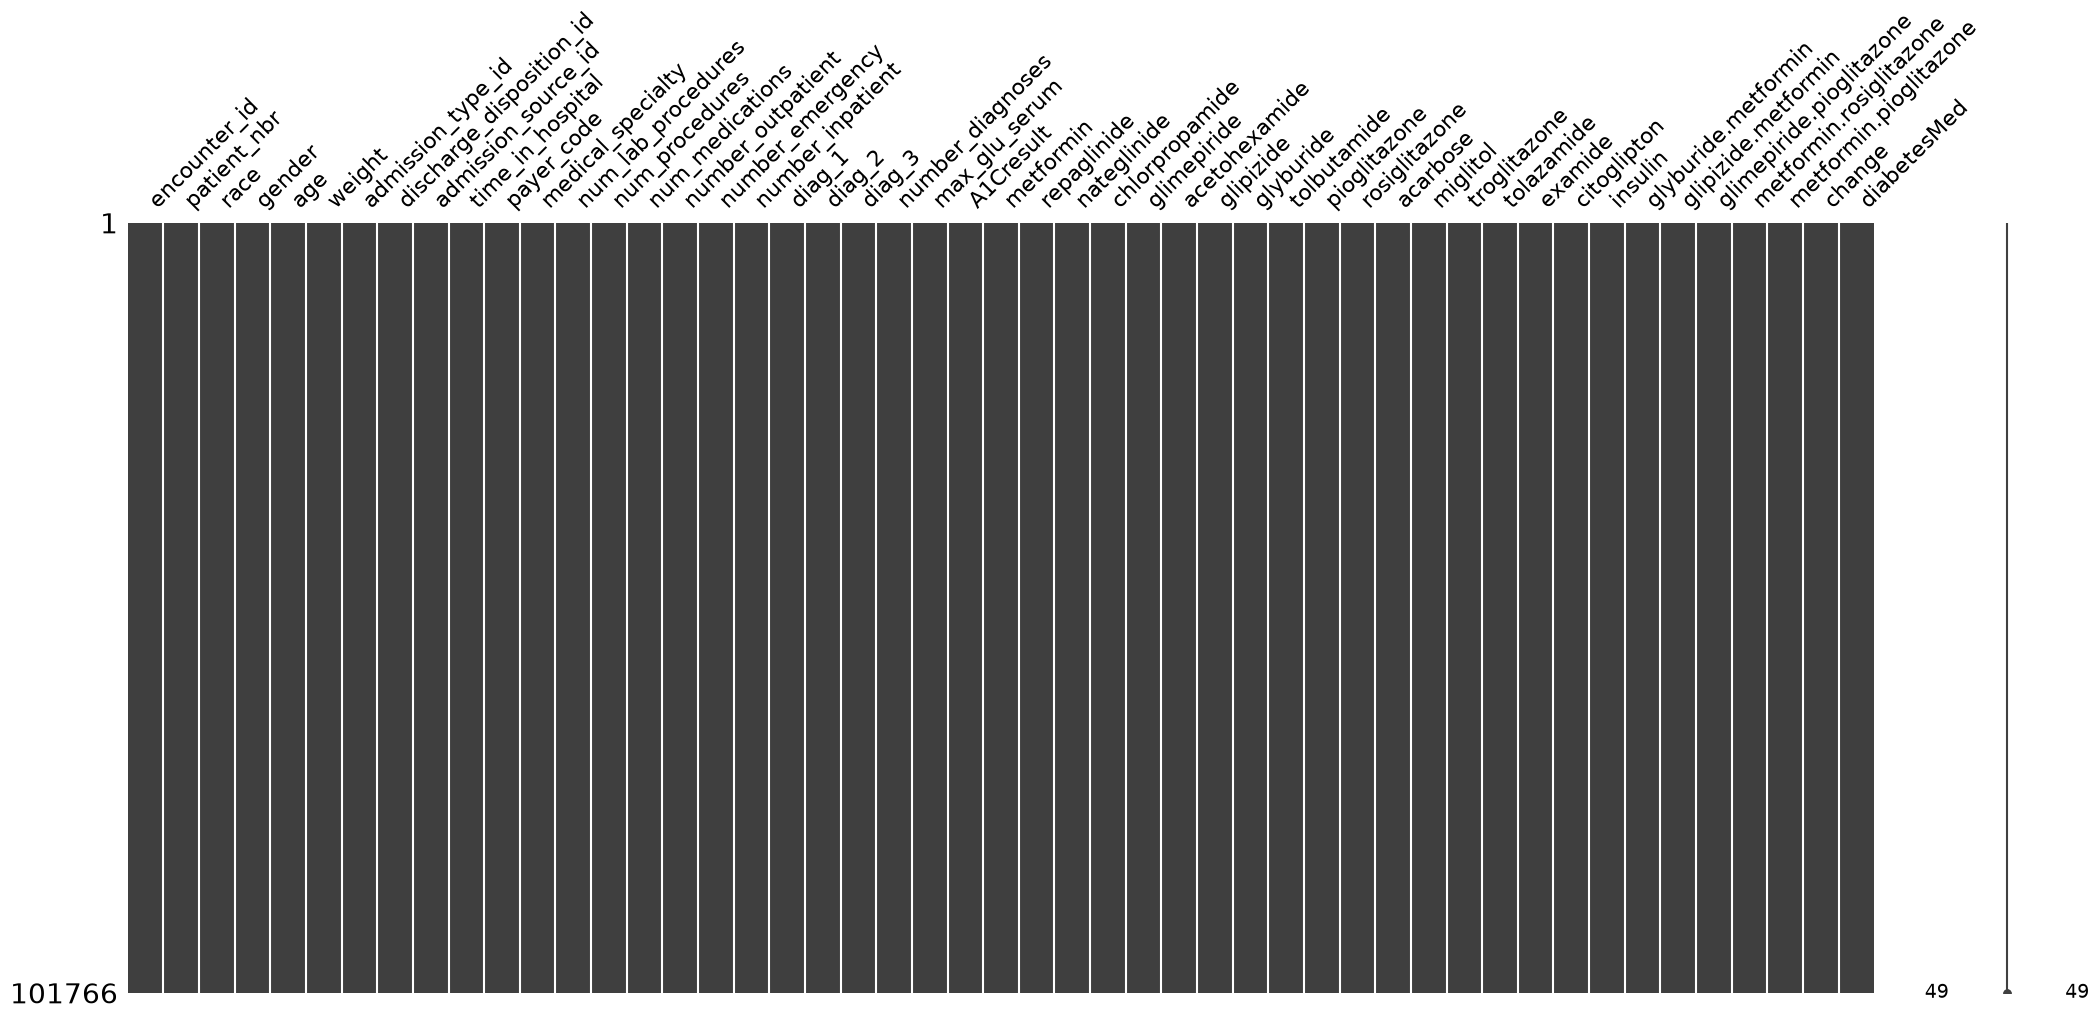

In [169]:
msno.matrix(df)

In [170]:
df.duplicated().sum()

np.int64(0)

##### Now we replace all the missing values with NaaN.

In [171]:
df = df.replace('?', np.nan)
df = df.replace('None', np.nan)
df = df.replace('Unknown/Invalid', np.nan)
df.isna().sum()

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          3
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

##### Now that we established that we have a lot of missing values, we will delete the top 5 columns because even if we fill with the mean, median or mode, the analysis will be flawed.

In [172]:
missing_percentage = df.isna().sum() / len(df) * 100
missing_percentage[missing_percentage > 0].sort_values(ascending=False).round(4)

weight               96.8585
max_glu_serum        94.7468
A1Cresult            83.2773
medical_specialty    49.0822
payer_code           39.5574
race                  2.2336
diag_3                1.3983
diag_2                0.3518
diag_1                0.0206
gender                0.0029
dtype: float64

In [173]:
df = df.drop(columns=['weight', 'max_glu_serum', 'A1Cresult', 'medical_specialty','payer_code'])

##### Now, we replace the last missing values.

In [174]:
df["race"] = df["race"].fillna(df["race"].mode()[0])
df["gender"] = df["gender"].fillna(df["gender"].mode()[0])

In [175]:
for col in ["diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].astype("string").fillna("Unknown")

<Axes: >

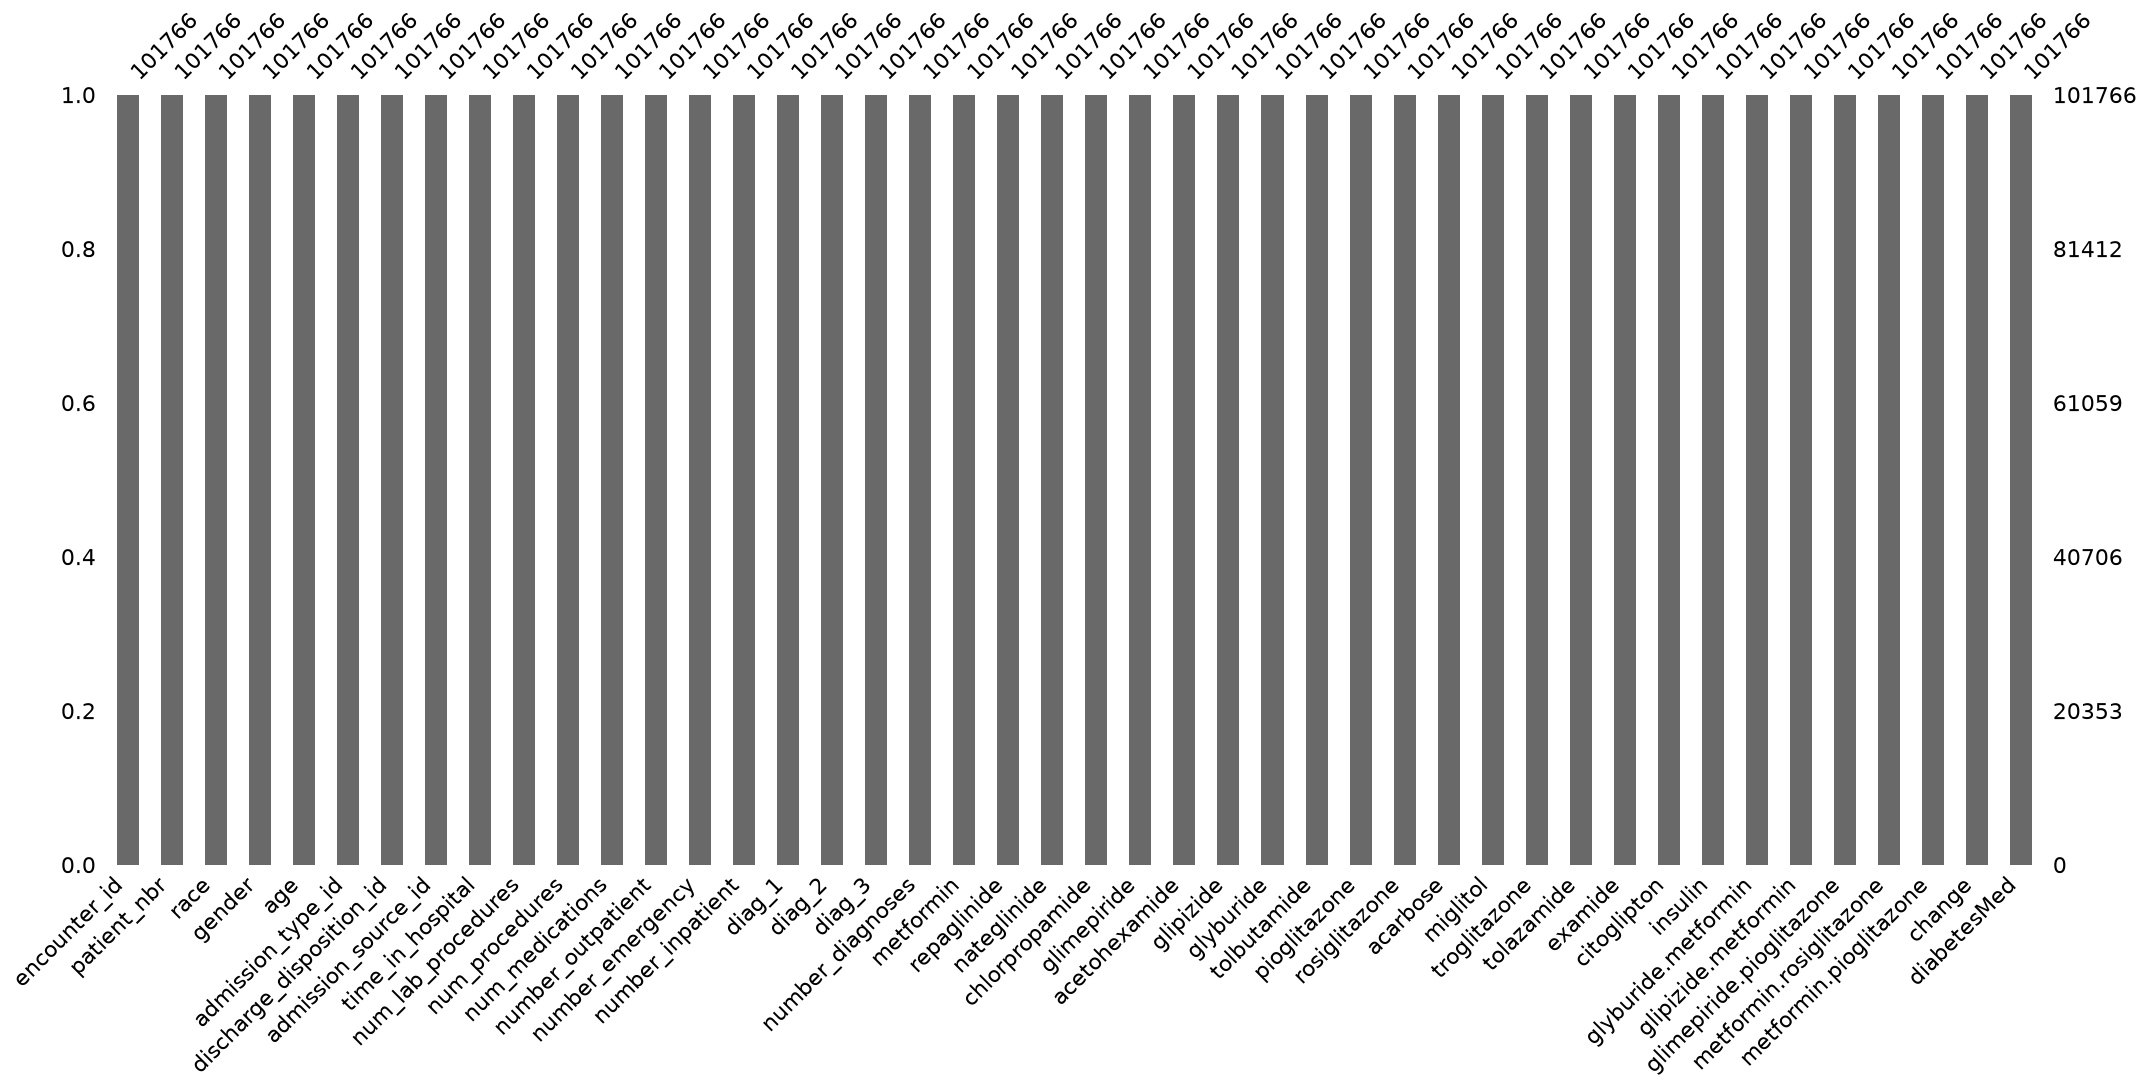

In [176]:
msno.bar(df)

### We run a df.describe on the diagnoses and see which diagnosis is most repititive. 
#### 1. Based on the information below, the main diagnosis is 428 which refers to heart failure :(
#### 2. Then, the second most common diagnosis is 276 which is disorder of fluid :(
#### 3. Finally, the third most common diagnosis is 250 which is Diabetes Mellitus :(

In [177]:
df[["diag_1", "diag_2", "diag_3"]].mode()

,diag_1,diag_2,diag_3
0,428,276,250


##### Visualize the binary target distribution in percentages.

In [178]:
y.value_counts(normalize=True) * 100

readmitted
0    53.911916
1    46.088084
Name: proportion, dtype: float64

# 1.5 Multivariate analysis

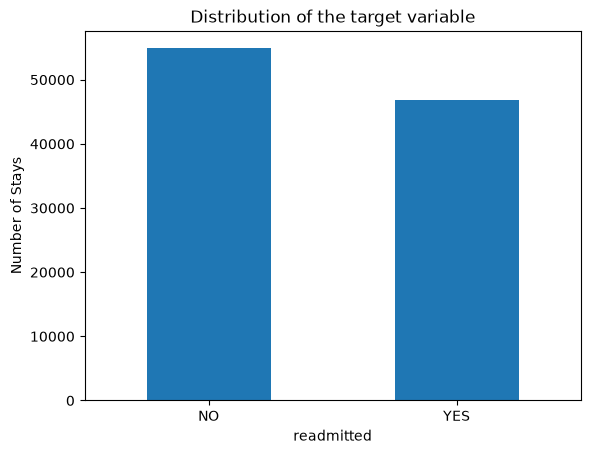

In [179]:
y.value_counts().sort_index().plot.bar()
plt.title("Distribution of the target variable")
plt.xticks([0, 1], ['NO', 'YES'], rotation=0)
plt.ylabel("Number of Stays")
plt.show()

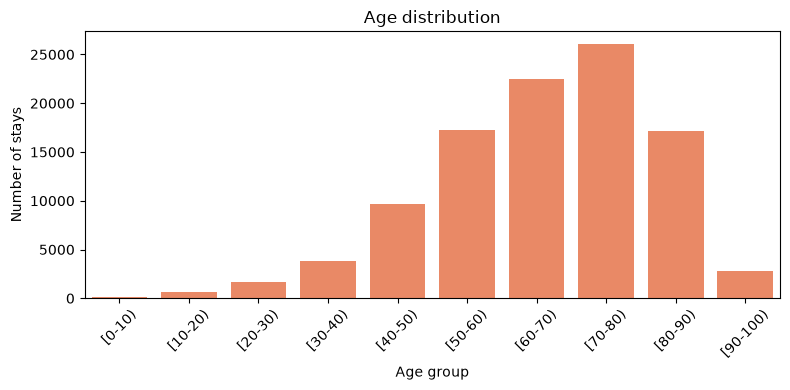

In [180]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="age", order=sorted(df["age"]), color="coral")
plt.title("Age distribution")
plt.xlabel("Age group")
plt.ylabel("Number of stays")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

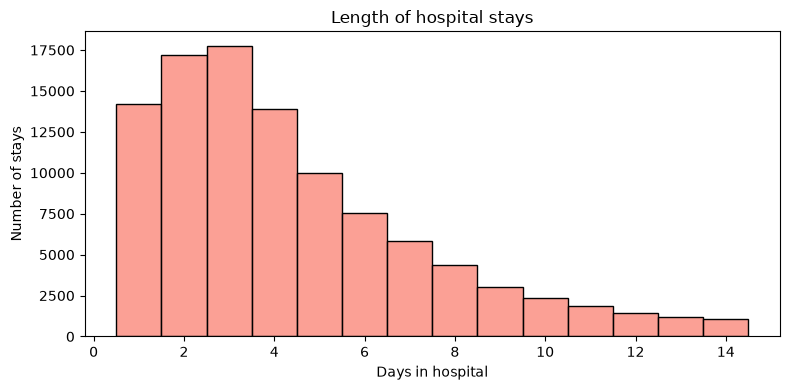

In [181]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="time_in_hospital", discrete=True, color="salmon")
plt.title("Length of hospital stays")
plt.xlabel("Days in hospital")
plt.ylabel("Number of stays")
plt.tight_layout()
plt.show()


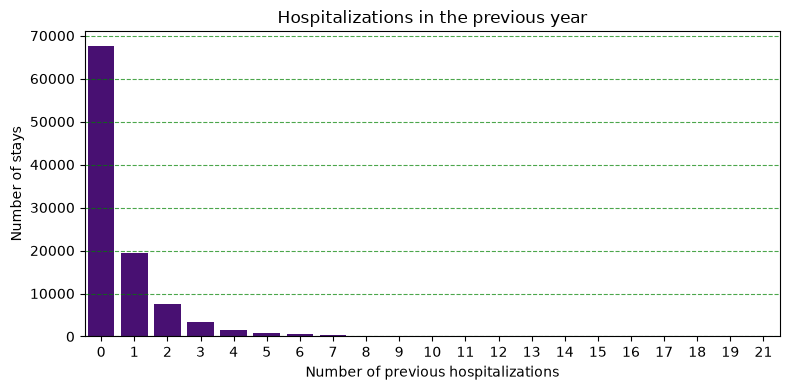

In [182]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="number_inpatient", color="indigo")
plt.grid(axis='y', linestyle='--', alpha=0.7, color='green')
plt.title("Hospitalizations in the previous year")
plt.xlabel("Number of previous hospitalizations")
plt.ylabel("Number of stays")
plt.tight_layout()
plt.show()

##### Now we look into the patients that have been admitted multiple times and patients that have been admitted only once.
##### To break down the maths, we take the number of patients with several stays and subtract it from the unique patients and then add the total stays for patients with several days, which gives us the total number of admissions (101,766).

In [183]:
stays_per_patient = df["patient_nbr"].value_counts()

print("Unique patients:", stays_per_patient.size)
print("Patients with several stays:", (stays_per_patient > 1).sum())
print("Total stays for patients with several stays:", stays_per_patient[stays_per_patient > 1].sum())

Unique patients: 71518
Patients with several stays: 16773
Total stays for patients with several stays: 47021


### EDA conclusion

Our goal is to predict whether a hospital stay will be followed by a recorded readmission, regardless of the delay. We plan to make predictions at discharge.

The target is binary: 1 for a recorded readmission (⁠ <30 ⁠ or ⁠ >30 ⁠) and 0 for no recorded readmission (⁠ NO ⁠). About 46% of stays belong to class 1, so the classes are relatively balanced.

The dataset contains 101,766 stays from 71,518 patients. Among these patients, 16,773 have multiple stays. We will therefore split the data by patient to prevent overlap between training and test sets.

Unknown diagnosis codes are represented by an "Unknown" category. Diagnosis codes and other category codes will be treated as categorical variables.

Next, we will split the data before fitting any imputation or encoding. Patient and encounter identifiers will be excluded from the model's predictors.